<a href="https://colab.research.google.com/github/em2tech/Machine_Learning_SJU/blob/main/HW6/faces_pca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**HW6 - PCA and Dimensionality Reduction on the Olivetti Faces Dataset.**

This notebook studies Principal Component Analysis (PCA) as an unsupervised, linear dimensionality-reduction technique applied to face images. It is organized into eight tasks that build on each other.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_olivetti_faces
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import (accuracy_score, mean_squared_error,
                             confusion_matrix, classification_report)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": False})

# Collects {model name: {"accuracy": ..., "train_time": ...}} for Task 8
results = {}

**Task 1: Dataset Loading and Dimensionality Inspection**


downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
OLIVETTI FACES - DATASET SUMMARY
Total number of samples      : 400
Unique target subjects       : 40
Feature dimensions per image : 4096  (64 x 64)
Images per subject           : 10 - 10
Pixel intensity range        : [0.000, 1.000]
X shape: (400, 4096) | y shape: (400,) | images shape: (400, 64, 64)


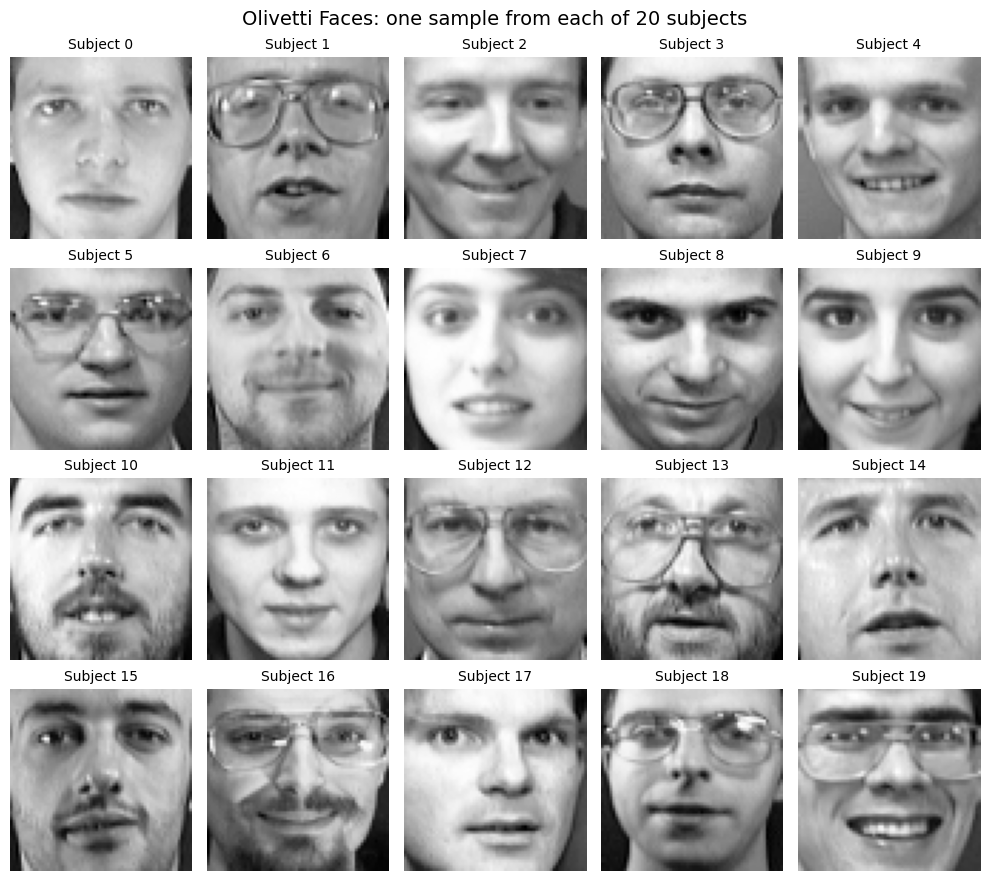

In [2]:
# Load the dataset (downloaded once, then cached)
faces = fetch_olivetti_faces(shuffle=False, random_state=RANDOM_STATE)

X = faces.data        # (400, 4096) flattened pixel vectors
y = faces.target      # (400,) subject IDs 0-39
images = faces.images # (400, 64, 64) 2-D images for display

n_samples, n_features = X.shape
n_subjects = len(np.unique(y))
img_h, img_w = images.shape[1], images.shape[2]

print("=" * 50)
print("OLIVETTI FACES - DATASET SUMMARY")
print("=" * 50)
print(f"Total number of samples      : {n_samples}")
print(f"Unique target subjects       : {n_subjects}")
print(f"Feature dimensions per image : {n_features}  ({img_h} x {img_w})")
print(f"Images per subject           : {np.bincount(y).min()} - {np.bincount(y).max()}")
print(f"Pixel intensity range        : [{X.min():.3f}, {X.max():.3f}]")
print(f"X shape: {X.shape} | y shape: {y.shape} | images shape: {images.shape}")

# 4 x 5 grid: the first image of each of the first 20 subjects
fig, axes = plt.subplots(4, 5, figsize=(10, 9))
for ax, subject in zip(axes.ravel(), range(20)):
    idx = subject * 10
    ax.imshow(images[idx], cmap="gray")
    ax.set_title(f"Subject {y[idx]}", fontsize=10)
    ax.axis("off")
fig.suptitle("Olivetti Faces: one sample from each of 20 subjects", fontsize=14)
plt.tight_layout()
plt.show()

**Task 2: Cumulative Explained Variance & Elbow Plot**


Total components in full PCA: 400

Components required to preserve cumulative variance:
  90% variance ->  66 components (1.61% of 4,096 dims, 62.1x compression)
  95% variance -> 123 components (3.00% of 4,096 dims, 33.3x compression)
  99% variance -> 260 components (6.35% of 4,096 dims, 15.8x compression)


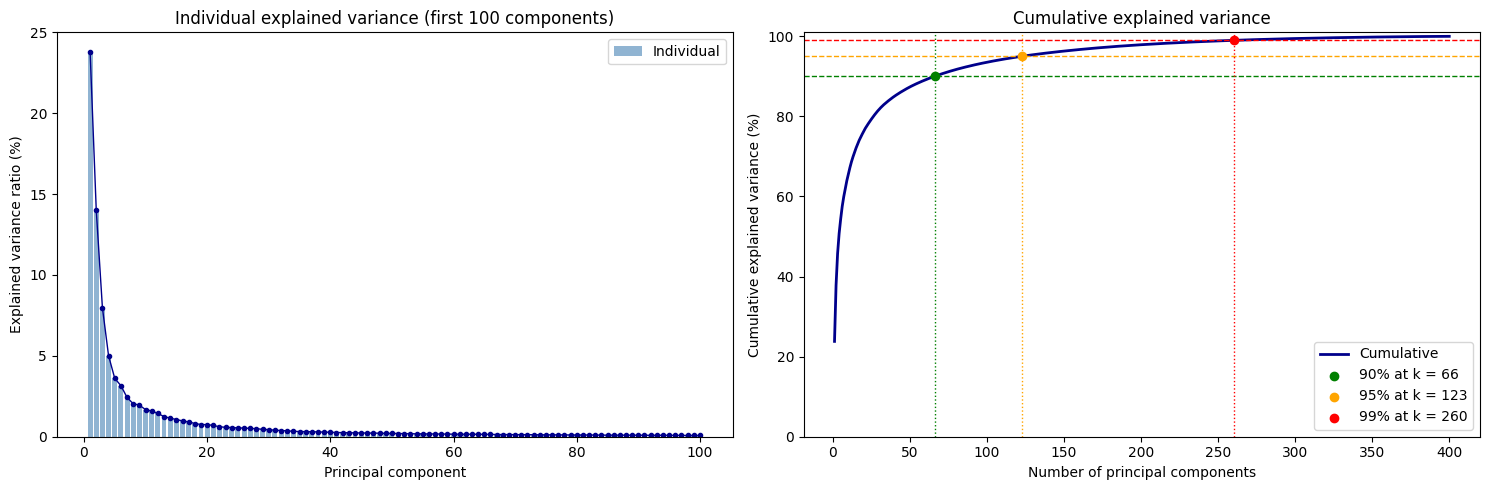

In [3]:
# Fit PCA with all possible components (max = min(400, 4096) = 400)
pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X)

evr = pca_full.explained_variance_ratio_
cumulative = np.cumsum(evr)
n_total = len(evr)
print(f"Total components in full PCA: {n_total}")

# Exact component counts for each variance threshold
thresholds = [0.90, 0.95, 0.99]
n_needed = {t: int(np.searchsorted(cumulative, t) + 1) for t in thresholds}

print("\nComponents required to preserve cumulative variance:")
for t, k in n_needed.items():
    print(f"  {int(t*100)}% variance -> {k:>3} components "
          f"({k/n_features*100:.2f}% of 4,096 dims, {n_features/k:.1f}x compression)")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: individual explained variance (elbow / scree plot)
show = 100
axes[0].bar(range(1, show + 1), evr[:show] * 100, color="steelblue", alpha=0.6, label="Individual")
axes[0].plot(range(1, show + 1), evr[:show] * 100, color="darkblue", marker=".", lw=1)
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Explained variance ratio (%)")
axes[0].set_title(f"Individual explained variance (first {show} components)")
axes[0].legend()

# Right: cumulative explained variance with threshold markers
colors = {0.90: "green", 0.95: "orange", 0.99: "red"}
axes[1].plot(range(1, n_total + 1), cumulative * 100, color="darkblue", lw=2, label="Cumulative")
for t, k in n_needed.items():
    axes[1].axhline(t * 100, color=colors[t], ls="--", lw=1)
    axes[1].axvline(k, color=colors[t], ls=":", lw=1)
    axes[1].scatter(k, cumulative[k - 1] * 100, color=colors[t], zorder=5,
                    label=f"{int(t*100)}% at k = {k}")
axes[1].set_xlabel("Number of principal components")
axes[1].set_ylabel("Cumulative explained variance (%)")
axes[1].set_title("Cumulative explained variance")
axes[1].set_ylim(0, 101)
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

**Task 3: Image Compression and Reconstruction Analysis**


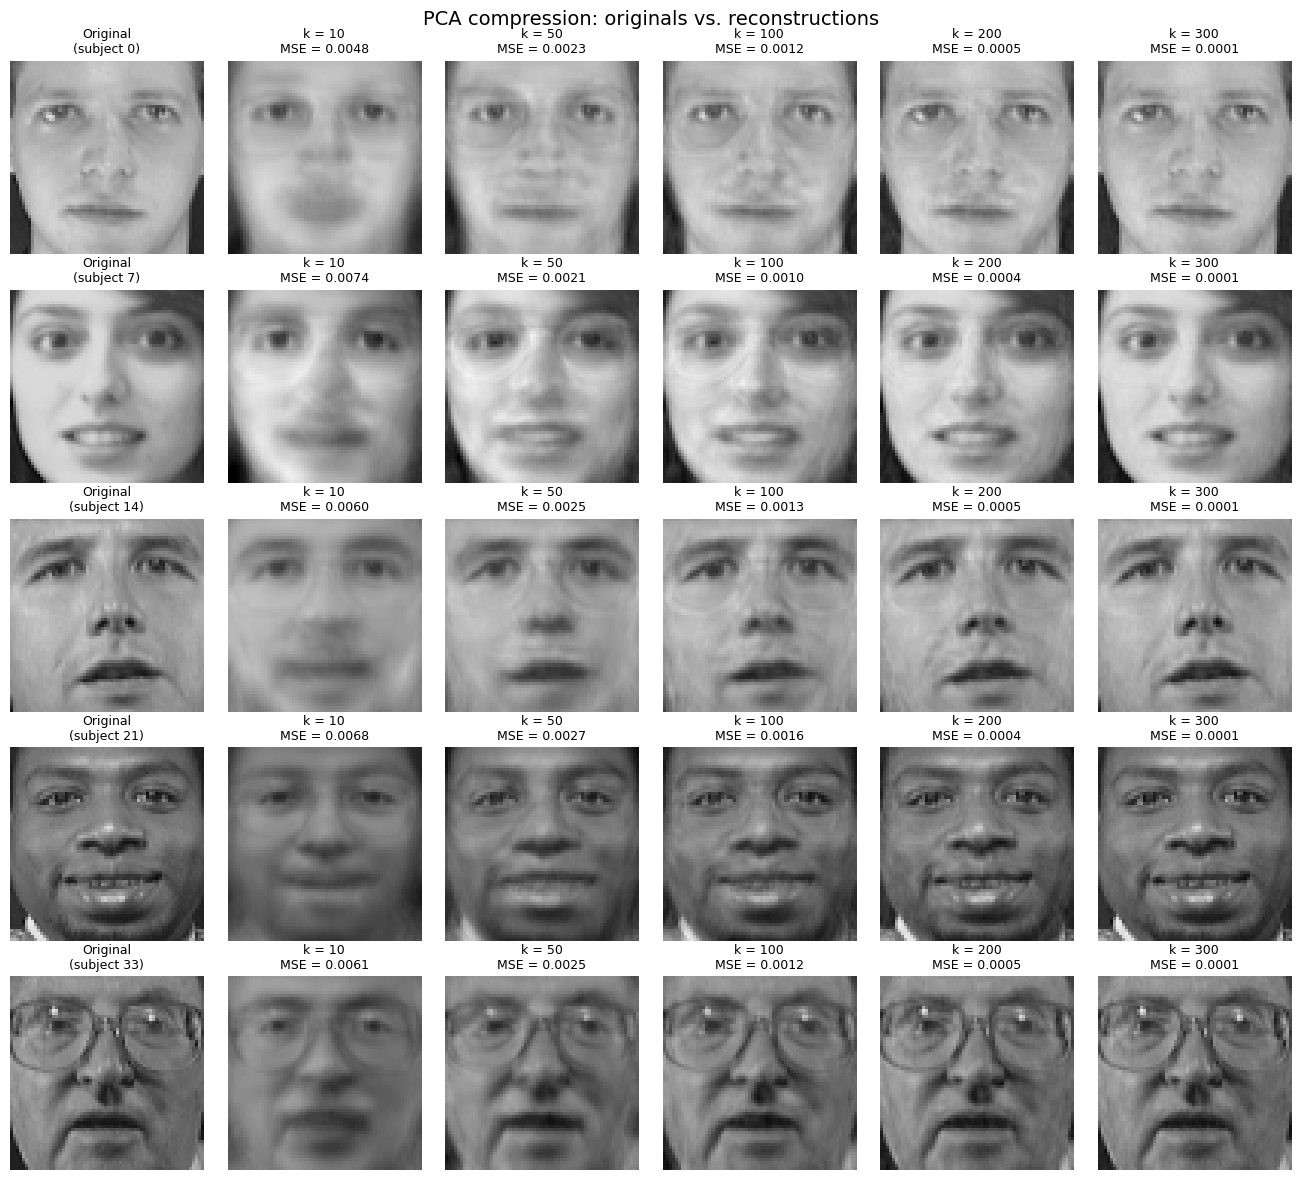

  k Compression (4096/k)  MSE (5 selected faces)  MSE (all 400 faces)
 10               409.6x                0.006209             0.006622
 50                81.9x                0.002415             0.002439
100                41.0x                0.001260             0.001252
200                20.5x                0.000451             0.000409
300                13.7x                0.000104             0.000107


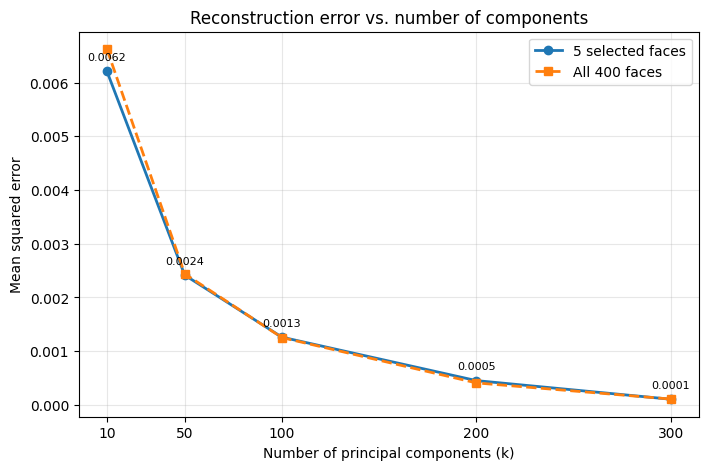

In [4]:
sample_idx = [0, 70, 140, 210, 330]   # 5 faces from 5 different subjects
k_values = [10, 50, 100, 200, 300]

reconstructions = {}
mse_samples, mse_all = [], []

for k in k_values:
    pca_k = PCA(n_components=k, random_state=RANDOM_STATE)
    X_compressed = pca_k.fit_transform(X)                  # (400, k)
    X_reconstructed = pca_k.inverse_transform(X_compressed)  # (400, 4096)
    reconstructions[k] = X_reconstructed
    mse_samples.append(mean_squared_error(X[sample_idx].T, X_reconstructed[sample_idx].T))
    mse_all.append(mean_squared_error(X.T, X_reconstructed.T))

# Grid: originals + reconstructions at each k
n_rows, n_cols = len(sample_idx), len(k_values) + 1
fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.2 * n_cols, 2.4 * n_rows))
for r, idx in enumerate(sample_idx):
    axes[r, 0].imshow(images[idx], cmap="gray", vmin=0, vmax=1)
    axes[r, 0].set_title(f"Original\n(subject {y[idx]})", fontsize=9)
    for c, k in enumerate(k_values, start=1):
        rec = reconstructions[k][idx].reshape(img_h, img_w)
        err = np.mean((X[idx] - reconstructions[k][idx]) ** 2)
        axes[r, c].imshow(rec, cmap="gray", vmin=0, vmax=1)
        axes[r, c].set_title(f"k = {k}\nMSE = {err:.4f}", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
fig.suptitle("PCA compression: originals vs. reconstructions", fontsize=14)
plt.tight_layout()
plt.show()

# MSE table and curve
mse_df = pd.DataFrame({"k": k_values,
                       "Compression (4096/k)": [f"{n_features/k:.1f}x" for k in k_values],
                       "MSE (5 selected faces)": mse_samples,
                       "MSE (all 400 faces)": mse_all})
print(mse_df.to_string(index=False, float_format=lambda v: f"{v:.6f}"))

plt.figure(figsize=(8, 5))
plt.plot(k_values, mse_samples, marker="o", lw=2, label="5 selected faces")
plt.plot(k_values, mse_all, marker="s", lw=2, ls="--", label="All 400 faces")
for k, m in zip(k_values, mse_samples):
    plt.annotate(f"{m:.4f}", (k, m), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
plt.xlabel("Number of principal components (k)")
plt.ylabel("Mean squared error")
plt.title("Reconstruction error vs. number of components")
plt.xticks(k_values)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Task 4: Visualization of "Eigenfaces"**

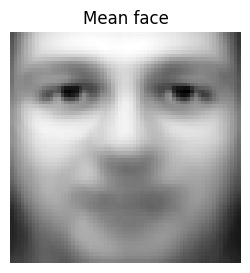

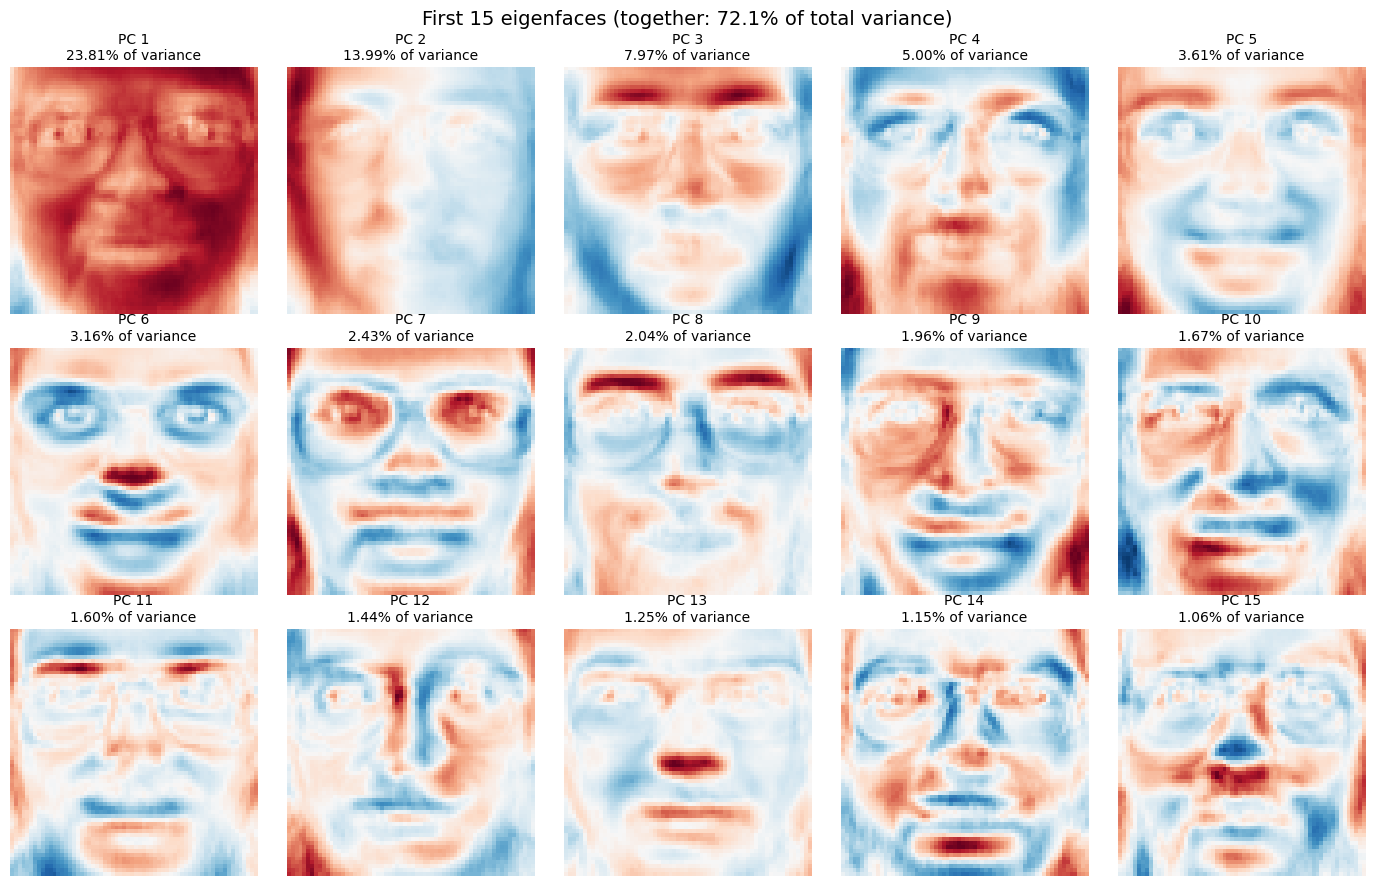

Variance explained by each of the first 15 components:
  PC  1:  23.81%   (cumulative  23.81%)
  PC  2:  13.99%   (cumulative  37.81%)
  PC  3:   7.97%   (cumulative  45.78%)
  PC  4:   5.00%   (cumulative  50.77%)
  PC  5:   3.61%   (cumulative  54.38%)
  PC  6:   3.16%   (cumulative  57.54%)
  PC  7:   2.43%   (cumulative  59.97%)
  PC  8:   2.04%   (cumulative  62.00%)
  PC  9:   1.96%   (cumulative  63.96%)
  PC 10:   1.67%   (cumulative  65.63%)
  PC 11:   1.60%   (cumulative  67.23%)
  PC 12:   1.44%   (cumulative  68.67%)
  PC 13:   1.25%   (cumulative  69.91%)
  PC 14:   1.15%   (cumulative  71.06%)
  PC 15:   1.06%   (cumulative  72.12%)


In [5]:
n_eig = 15
eigenfaces = pca_full.components_[:n_eig].reshape(n_eig, img_h, img_w)
eig_var_pct = pca_full.explained_variance_ratio_[:n_eig] * 100

# Mean face (the origin of the PCA coordinate system)
plt.figure(figsize=(3, 3))
plt.imshow(pca_full.mean_.reshape(img_h, img_w), cmap="gray")
plt.title("Mean face")
plt.axis("off")
plt.show()

# First 15 eigenfaces in a 3 x 5 grid
fig, axes = plt.subplots(3, 5, figsize=(14, 9))
for i, ax in enumerate(axes.ravel()):
    lim = np.abs(eigenfaces[i]).max()
    ax.imshow(eigenfaces[i], cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set_title(f"PC {i+1}\n{eig_var_pct[i]:.2f}% of variance", fontsize=10)
    ax.axis("off")
fig.suptitle(f"First {n_eig} eigenfaces "
             f"(together: {eig_var_pct.sum():.1f}% of total variance)", fontsize=14)
plt.tight_layout()
plt.show()

print("Variance explained by each of the first 15 components:")
for i, v in enumerate(eig_var_pct, 1):
    print(f"  PC {i:>2}: {v:6.2f}%   (cumulative {eig_var_pct[:i].sum():6.2f}%)")

**Task 5: Classification Baseline — Raw vs. PCA-Reduced Features (Linear Model)**

Train: (320, 4096), Test: (80, 4096)
Images per subject -> train: 8, test: 2

PCA (fit on training set) keeps 111 components for 95.01% of training variance
Dimensionality: 4096 -> 111  (36.9x smaller)

Model                         Features   Accuracy Train time (s)
--------------------------------------------------------------
LogReg (Raw)                      4096     0.9625        20.7324
LogReg (PCA 95%)                   111     0.9625         0.2262
One-off PCA fitting time (shared by all PCA models): 0.3404 s
Speed-up of PCA model vs. raw model: 91.7x


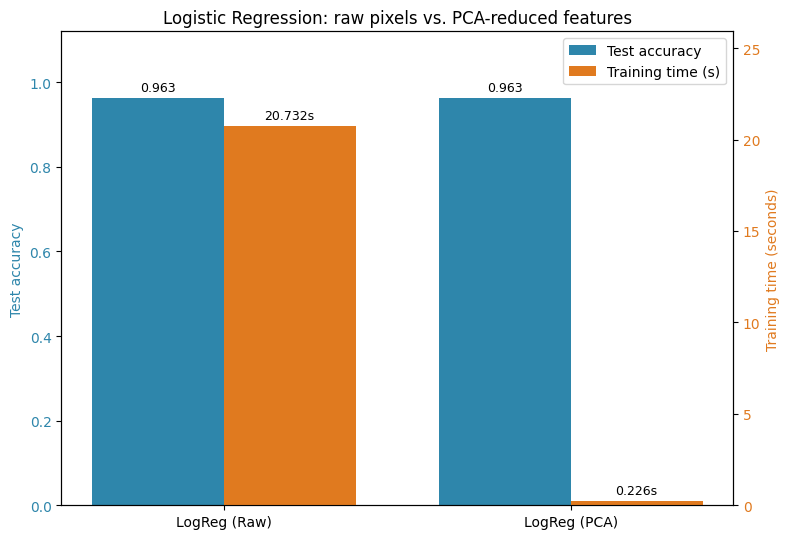

In [6]:
# 1. Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Images per subject -> train: {np.bincount(y_train)[0]}, test: {np.bincount(y_test)[0]}")

# 2. Logistic Regression on raw 4,096-dim pixels
lr_raw = LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)
t0 = time.perf_counter()
lr_raw.fit(X_train, y_train)
t_lr_raw = time.perf_counter() - t0
y_pred_lr_raw = lr_raw.predict(X_test)
acc_lr_raw = accuracy_score(y_test, y_pred_lr_raw)

# 3. PCA (95% variance) fitted ONLY on the training split
pca95 = PCA(n_components=0.95, svd_solver="full", random_state=RANDOM_STATE)
t0 = time.perf_counter()
X_train_pca = pca95.fit_transform(X_train)
t_pca_fit = time.perf_counter() - t0
X_test_pca = pca95.transform(X_test)   # transform only, never fit on test data
n_pca = pca95.n_components_
print(f"\nPCA (fit on training set) keeps {n_pca} components "
      f"for {pca95.explained_variance_ratio_.sum()*100:.2f}% of training variance")
print(f"Dimensionality: 4096 -> {n_pca}  ({n_features/n_pca:.1f}x smaller)")

# 4. Logistic Regression on PCA-reduced features
lr_pca = LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)
t0 = time.perf_counter()
lr_pca.fit(X_train_pca, y_train)
t_lr_pca = time.perf_counter() - t0
y_pred_lr_pca = lr_pca.predict(X_test_pca)
acc_lr_pca = accuracy_score(y_test, y_pred_lr_pca)

results["LogReg (Raw)"] = {"accuracy": acc_lr_raw, "train_time": t_lr_raw}
results["LogReg (PCA)"] = {"accuracy": acc_lr_pca, "train_time": t_lr_pca}

print("\n" + "=" * 62)
print(f"{'Model':<28}{'Features':>10}{'Accuracy':>11}{'Train time (s)':>15}")
print("-" * 62)
print(f"{'LogReg (Raw)':<28}{n_features:>10}{acc_lr_raw:>11.4f}{t_lr_raw:>15.4f}")
print(f"{'LogReg (PCA 95%)':<28}{n_pca:>10}{acc_lr_pca:>11.4f}{t_lr_pca:>15.4f}")
print("=" * 62)
print(f"One-off PCA fitting time (shared by all PCA models): {t_pca_fit:.4f} s")
print(f"Speed-up of PCA model vs. raw model: {t_lr_raw / t_lr_pca:.1f}x")


def dual_axis_bar(res, title):
    # Accuracy bars (left axis) next to training-time bars (right axis)
    names = list(res.keys())
    accs = [res[n]["accuracy"] for n in names]
    times = [res[n]["train_time"] for n in names]
    x = np.arange(len(names))
    w = 0.38

    fig, ax1 = plt.subplots(figsize=(max(8, 2.6 * len(names)), 5.5))
    b1 = ax1.bar(x - w / 2, accs, w, color="#2E86AB", label="Test accuracy")
    ax1.set_ylabel("Test accuracy", color="#2E86AB")
    ax1.set_ylim(0, 1.12)
    ax1.tick_params(axis="y", labelcolor="#2E86AB")

    ax2 = ax1.twinx()
    b2 = ax2.bar(x + w / 2, times, w, color="#E07A1F", label="Training time (s)")
    ax2.set_ylabel("Training time (seconds)", color="#E07A1F")
    ax2.set_ylim(0, max(times) * 1.25)
    ax2.tick_params(axis="y", labelcolor="#E07A1F")

    for bar, a in zip(b1, accs):
        ax1.text(bar.get_x() + bar.get_width() / 2, a + 0.01, f"{a:.3f}",
                 ha="center", va="bottom", fontsize=9)
    for bar, t in zip(b2, times):
        ax2.text(bar.get_x() + bar.get_width() / 2, t + max(times) * 0.01, f"{t:.3f}s",
                 ha="center", va="bottom", fontsize=9)

    ax1.set_xticks(x)
    ax1.set_xticklabels(names)
    ax1.set_title(title)
    ax1.legend([b1, b2], ["Test accuracy", "Training time (s)"], loc="upper right")
    plt.tight_layout()
    plt.show()


dual_axis_bar(results, "Logistic Regression: raw pixels vs. PCA-reduced features")

**Task 6: Non-Linear Classification (Kernel SVM)**

        Model  Accuracy  Train time (s)  Errors (of 80)
 LogReg (PCA)    0.9625          0.2262               3
SVC-RBF (PCA)    0.9750          0.1414               2

Test images where the two models disagree: 2
  ...LogReg correct there: 0
  ...SVC-RBF correct there: 1
LogReg (PCA)    macro precision 0.975 | recall 0.963 | F1 0.960
SVC-RBF (PCA)   macro precision 0.983 | recall 0.975 | F1 0.973


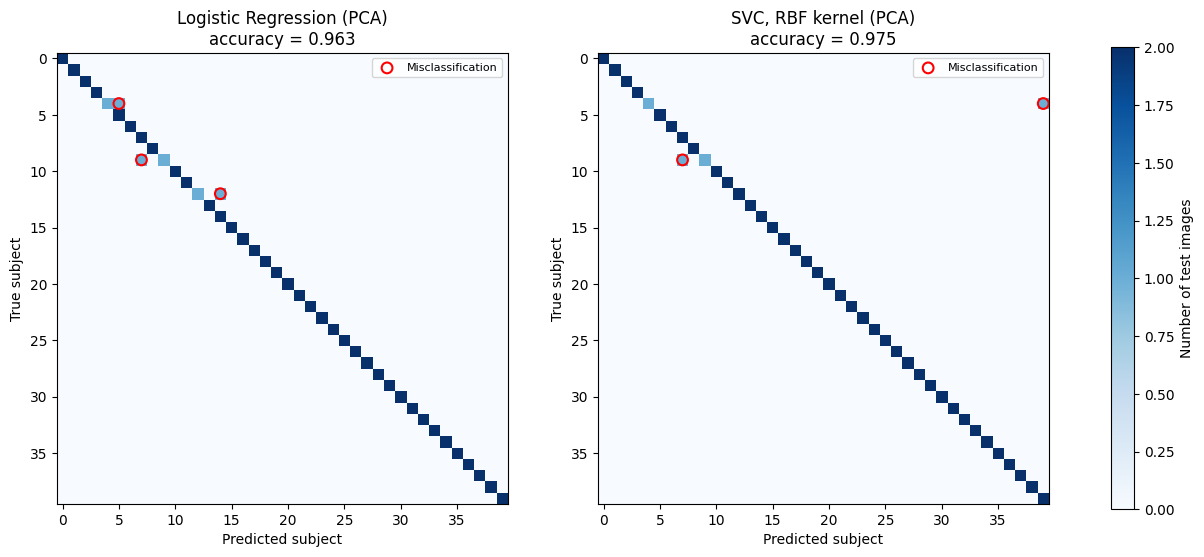

In [7]:
svc_rbf = SVC(kernel="rbf", C=10, gamma="scale", random_state=RANDOM_STATE)
t0 = time.perf_counter()
svc_rbf.fit(X_train_pca, y_train)
t_svc = time.perf_counter() - t0
y_pred_svc = svc_rbf.predict(X_test_pca)
acc_svc = accuracy_score(y_test, y_pred_svc)
results["SVC-RBF (PCA)"] = {"accuracy": acc_svc, "train_time": t_svc}

# Side-by-side summary vs. the linear baseline
summary = pd.DataFrame({
    "Model": ["LogReg (PCA)", "SVC-RBF (PCA)"],
    "Accuracy": [acc_lr_pca, acc_svc],
    "Train time (s)": [t_lr_pca, t_svc],
    "Errors (of 80)": [(y_pred_lr_pca != y_test).sum(), (y_pred_svc != y_test).sum()],
})
print(summary.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

disagree = y_pred_lr_pca != y_pred_svc
print(f"\nTest images where the two models disagree: {disagree.sum()}")
print(f"  ...LogReg correct there: {(y_pred_lr_pca[disagree] == y_test[disagree]).sum()}")
print(f"  ...SVC-RBF correct there: {(y_pred_svc[disagree] == y_test[disagree]).sum()}")

# Macro-averaged precision / recall / F1
for name, pred in [("LogReg (PCA)", y_pred_lr_pca), ("SVC-RBF (PCA)", y_pred_svc)]:
    rep = classification_report(y_test, pred, output_dict=True, zero_division=0)
    m = rep["macro avg"]
    print(f"{name:<15} macro precision {m['precision']:.3f} | "
          f"recall {m['recall']:.3f} | F1 {m['f1-score']:.3f}")

# Confusion matrices side by side
labels = np.arange(n_subjects)
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))
for ax, (name, pred, acc) in zip(axes, [("Logistic Regression (PCA)", y_pred_lr_pca, acc_lr_pca),
                                        ("SVC, RBF kernel (PCA)", y_pred_svc, acc_svc)]):
    cm = confusion_matrix(y_test, pred, labels=labels)
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=2)
    off = np.argwhere((cm > 0) & ~np.eye(n_subjects, dtype=bool))
    ax.scatter(off[:, 1], off[:, 0], s=60, facecolors="none", edgecolors="red", lw=1.5,
               label="Misclassification")
    ax.set_title(f"{name}\naccuracy = {acc:.3f}")
    ax.set_xlabel("Predicted subject")
    ax.set_ylabel("True subject")
    ax.set_xticks(labels[::5])
    ax.set_yticks(labels[::5])
    ax.legend(loc="upper right", fontsize=8)
fig.colorbar(im, ax=axes, shrink=0.8, label="Number of test images")
plt.show()

**Task 7: Ensemble Classification on PCA Features**

In [8]:
poly_svm = SVC(kernel="poly", degree=2, C=10, gamma="scale",
               probability=True, random_state=RANDOM_STATE)
rbf_svm = SVC(kernel="rbf", C=10, gamma="scale",
              probability=True, random_state=RANDOM_STATE)
rf = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)

ensemble = VotingClassifier(
    estimators=[("poly_svm", poly_svm), ("rbf_svm", rbf_svm), ("random_forest", rf)],
    voting="soft")

t0 = time.perf_counter()
ensemble.fit(X_train_pca, y_train)
t_ens = time.perf_counter() - t0
y_pred_ens = ensemble.predict(X_test_pca)
acc_ens = accuracy_score(y_test, y_pred_ens)
results["Soft Voting Ensemble (PCA)"] = {"accuracy": acc_ens, "train_time": t_ens}

# Accuracy of each member (as fitted inside the ensemble)
print("Individual ensemble members (PCA features):")
for name, est in ensemble.named_estimators_.items():
    print(f"  {name:<15} accuracy = {accuracy_score(y_test, est.predict(X_test_pca)):.4f}")

comparison = pd.DataFrame({
    "Model": ["LogReg (PCA)", "SVC-RBF (PCA)", "Soft Voting Ensemble (PCA)"],
    "Type": ["Linear", "Non-linear kernel", "Ensemble"],
    "Accuracy": [acc_lr_pca, acc_svc, acc_ens],
    "Train time (s)": [t_lr_pca, t_svc, t_ens],
    "Errors (of 80)": [(y_pred_lr_pca != y_test).sum(),
                       (y_pred_svc != y_test).sum(),
                       (y_pred_ens != y_test).sum()],
})
print()
print(comparison.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"\nEnsemble vs. LogReg (PCA): {(acc_ens - acc_lr_pca)*100:+.2f} accuracy points, "
      f"{t_ens / t_lr_pca:.1f}x the training time")
print(f"Ensemble vs. SVC-RBF (PCA): {(acc_ens - acc_svc)*100:+.2f} accuracy points, "
      f"{t_ens / t_svc:.1f}x the training time")

Individual ensemble members (PCA features):
  poly_svm        accuracy = 0.9500
  rbf_svm         accuracy = 0.9750
  random_forest   accuracy = 0.9375

                     Model              Type  Accuracy  Train time (s)  Errors (of 80)
              LogReg (PCA)            Linear    0.9625          0.2262               3
             SVC-RBF (PCA) Non-linear kernel    0.9750          0.1414               2
Soft Voting Ensemble (PCA)          Ensemble    0.9625          1.4809               3

Ensemble vs. LogReg (PCA): +0.00 accuracy points, 6.5x the training time
Ensemble vs. SVC-RBF (PCA): -1.25 accuracy points, 10.5x the training time


**Task 8: Comprehensive Comparative Evaluation**

                     Model  Input features  Accuracy  Train time (s) Relative time
              LogReg (Raw)            4096    0.9625         20.7324        146.6x
              LogReg (PCA)             111    0.9625          0.2262          1.6x
             SVC-RBF (PCA)             111    0.9750          0.1414          1.0x
Soft Voting Ensemble (PCA)             111    0.9625          1.4809         10.5x

(PCA fitting, done once for all PCA models: 0.3404 s)
Most accurate model : SVC-RBF (PCA) (0.9750)
Fastest to train    : SVC-RBF (PCA) (0.1414 s)


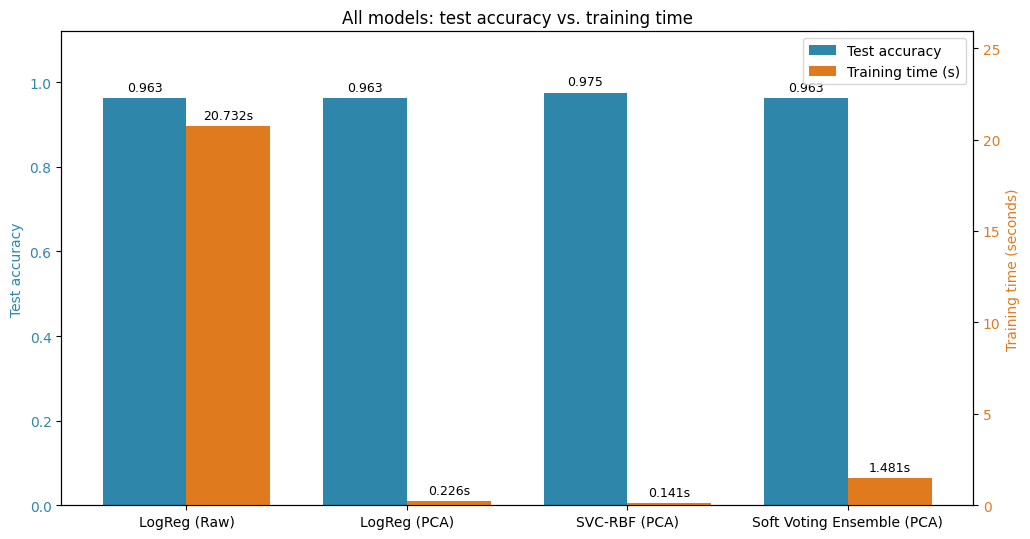

In [9]:
features_used = {"LogReg (Raw)": n_features, "LogReg (PCA)": n_pca,
                 "SVC-RBF (PCA)": n_pca, "Soft Voting Ensemble (PCA)": n_pca}
fastest = min(r["train_time"] for r in results.values())

final_df = pd.DataFrame([
    {"Model": name,
     "Input features": features_used[name],
     "Accuracy": r["accuracy"],
     "Train time (s)": r["train_time"],
     "Relative time": f"{r['train_time'] / fastest:.1f}x"}
    for name, r in results.items()])
print(final_df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"\n(PCA fitting, done once for all PCA models: {t_pca_fit:.4f} s)")

best = max(results, key=lambda n: results[n]["accuracy"])
quickest = min(results, key=lambda n: results[n]["train_time"])
print(f"Most accurate model : {best} ({results[best]['accuracy']:.4f})")
print(f"Fastest to train    : {quickest} ({results[quickest]['train_time']:.4f} s)")

dual_axis_bar(results, "All models: test accuracy vs. training time")